# Customer Churn Prediction

Goal: predict which customers of a telecom company will cancel their service, using contract type, monthly charges, tenure and tech support usage.

Data: Telco Customer Churn (IBM).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, ConfusionMatrixDisplay

df = pd.read_csv("../data/Telco-Customer-Churn.csv")
print(df.shape)
df[["Contract", "MonthlyCharges", "tenure", "TechSupport", "Churn"]].head()

(7043, 21)


,Contract,MonthlyCharges,tenure,TechSupport,Churn
0,Month-to-month,29.85,1,No,No
1,One year,56.95,34,No,No
2,Month-to-month,53.85,2,No,Yes
3,One year,42.30,45,Yes,No
4,Month-to-month,70.70,2,No,Yes


## 1. Exploring the data

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


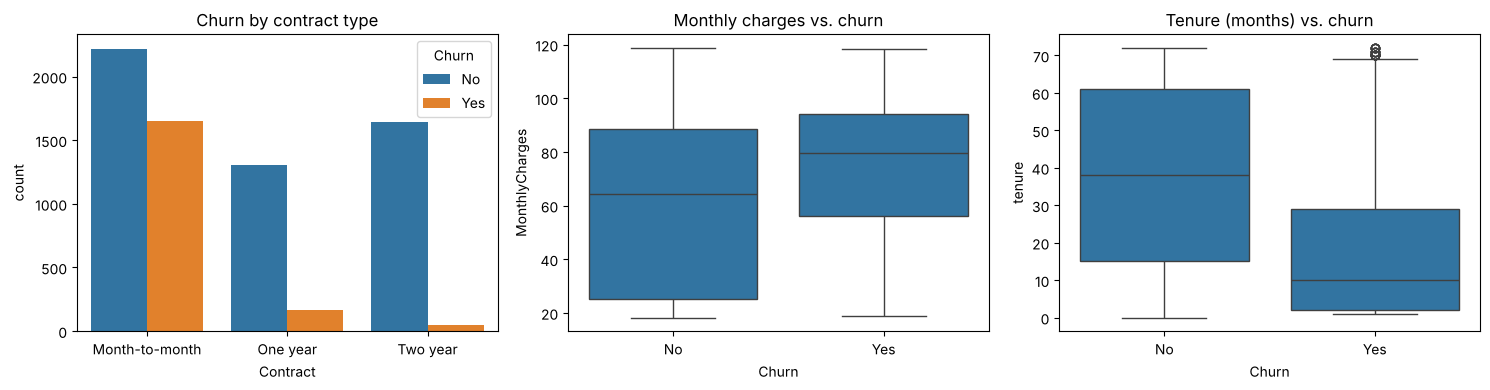

In [2]:
print(df["Churn"].value_counts(normalize=True).round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[0])
axes[0].set_title("Churn by contract type")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1])
axes[1].set_title("Monthly charges vs. churn")
sns.boxplot(data=df, x="Churn", y="tenure", ax=axes[2])
axes[2].set_title("Tenure (months) vs. churn")
plt.tight_layout()
plt.savefig("../images/exploration.png", dpi=100)
plt.show()

## 2. Preparing the data

We convert text columns to numbers (one-hot encoding) and the target column `Churn` to 0/1.

In [3]:
features = ["Contract", "MonthlyCharges", "tenure", "TechSupport"]
X = pd.get_dummies(df[features], drop_first=True)
y = (df["Churn"] == "Yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X.head()

,MonthlyCharges,tenure,Contract_One year,Contract_Two year,TechSupport_No internet service,TechSupport_Yes
0,29.85,1,False,False,False,False
1,56.95,34,True,False,False,False
2,53.85,2,False,False,False,False
3,42.30,45,True,False,False,True
4,70.70,2,False,False,False,False


## 3. Training the models

In [4]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, pred), 3),
        "Recall (churn)": round(recall_score(y_test, pred), 3),
    })

pd.DataFrame(results)

,Model,Accuracy,Recall (churn)
0,Logistic Regression,0.779,0.492
1,Random Forest,0.792,0.457


**Recall** shows how many of the customers who actually churned the model caught, which is what matters most for the company to act in time.

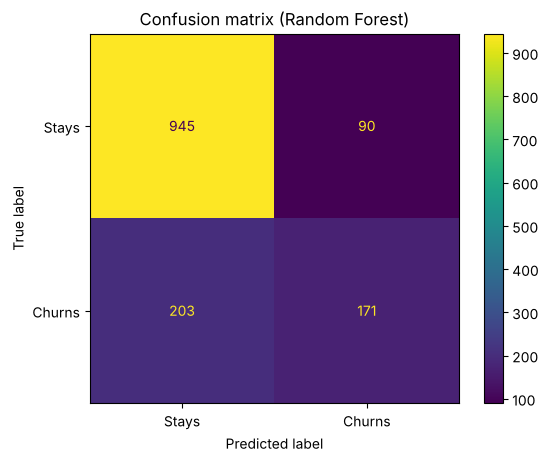

In [5]:
ConfusionMatrixDisplay.from_estimator(
    models["Random Forest"], X_test, y_test, display_labels=["Stays", "Churns"]
)
plt.title("Confusion matrix (Random Forest)")
plt.savefig("../images/confusion_matrix.png", dpi=100)
plt.show()

## 4. Conclusions

- Customers on month-to-month contracts churn far more than those on one- or two-year contracts.
- New customers (few months of tenure) with high monthly charges are at the highest risk.
- Next steps: use more columns from the dataset and tune the decision threshold to raise recall.